# Data quality of Madrid's urban traffic sensors, 2022–2023

This notebook derives the data rules used by every later stage: the clock-change rows, the
minimum samples per reading (k), the fixed sensor panel, the flow limit and the valid district slot.
Every fitted setting uses the training year (2022). The validation year (2023) appears only in the
descriptive checks of Sections 3–4, and the test year (2024) is never read. The rules are constants
in `config.py`, applied by `madrid_congestion.districts`; Sections 6 and 8 check that the package's
panel and district series match the rules derived here.

## 1. Setup
Months analysed, a trial month (March 2022) for checking each method before the full training year,
and a check that every input file exists.

In [1]:
import calendar
from datetime import date, datetime, time, timedelta

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from madrid_congestion.config import (
    DISTRICT_MINIMUM,
    DST_ROWS,
    EDA_YEARS,
    EXTERNAL_DATA_DIR,
    INTERIM_DATA_DIR,
    LOCATION_FILES,
    MAX_FLOW,
    MIN_SAMPLES,
    PANEL_CUTOFFS,
    PROCESSED_DATA_DIR,
    SAMPLES_FULL,
    SLOT,
    URB,
)
from madrid_congestion.districts import (
    FLOW_PLAUSIBLE,
    PANEL_PATH,
    SAMPLES_OK,
    VALID_READING,
    VALUES_PRESENT,
    combine_locations,
    month_urb_rows,
    panel_cutoff,
    read_locations,
    select_panel,
)
from madrid_congestion.plots import (
    CATEGORY_COLORS,
    LINE_WIDTH,
    REFERENCE,
    REFERENCE_WIDTH,
    save_figure,
    style_axes,
)

pl.Config.set_tbl_rows(20)  # show up to 20 table rows, so all 16 sample counts are visible

polars.config.Config

In [2]:
EDA_MONTHS = [f"{year}-{month:02d}" for year in EDA_YEARS for month in range(1, 13)]  # 2022-01 … 2023-12
# fitted settings (k, the panel) use 2022 only
MONTHS_2022 = [month for month in EDA_MONTHS if month.startswith("2022")]
TRIAL_MONTH = "2022-03"  # one month to look at and try each method on before running it on all of 2022
SLOTS_PER_DAY = timedelta(days=1) // SLOT  # 96 fifteen-minute slots in a day
EDA_PERIOD = f"{EDA_YEARS[0]}-{EDA_YEARS[-1]}"  # for figure titles

assert not any(month.startswith("2024") for month in EDA_MONTHS)  # 2024 is the locked test year
print(len(EDA_MONTHS), EDA_MONTHS[0], EDA_MONTHS[-1], len(MONTHS_2022), TRIAL_MONTH, SLOTS_PER_DAY)

24 2022-01 2023-12 12 2022-03 96


In [3]:
# Every file the steps below read must exist; the madrid_congestion.dataset commands make them (README).
monthly_paths = [INTERIM_DATA_DIR / f"{month}.parquet" for month in EDA_MONTHS]  # `download`, `convert`
location_paths = [EXTERNAL_DATA_DIR / f"locations-{month}.csv" for month in LOCATION_FILES]  # `download-locations`
missing = [path.name for path in monthly_paths + location_paths if not path.exists()]
assert not missing, f"missing input files: {missing}"
print(len(monthly_paths), "monthly files and", len(location_paths), "location files found")

24 monthly files and 2 location files found


## 2. Structure of the source data
Each row is one sensor (`id`, the city's *punto de medida*) in one 15-minute slot. Columns used:
- `fecha`: end of the slot;
- `tipo_elem`: `URB` (urban streets) or `M30` (ring road);
- `intensidad`: **flow**, vehicles per hour;
- `ocupacion`: **occupancy**, % of the slot a vehicle is over the detector (whole percent);
- `periodo_integracion`: one-minute samples received (15 = complete).

In [4]:
OVERVIEW_FILE = INTERIM_DATA_DIR / f"{TRIAL_MONTH}.parquet"  # March 2022, the trial month

pl.scan_parquet(OVERVIEW_FILE).head(10).collect()

id,fecha,tipo_elem,intensidad,ocupacion,carga,vmed,error,periodo_integracion
i32,datetime[μs],str,i32,i16,i16,i16,str,i8
1001,2022-03-01 00:00:00,"""M30""",408,2,0,52,"""N""",5
1001,2022-03-01 00:15:00,"""M30""",336,1,0,38,"""N""",5
1001,2022-03-01 00:30:00,"""M30""",276,2,0,37,"""N""",5
1001,2022-03-01 00:45:00,"""M30""",252,0,0,45,"""N""",5
1001,2022-03-01 01:00:00,"""M30""",312,1,0,51,"""N""",5
1001,2022-03-01 01:15:00,"""M30""",168,null,0,43,"""N""",5
1001,2022-03-01 01:30:00,"""M30""",168,0,0,54,"""N""",5
1001,2022-03-01 01:45:00,"""M30""",120,0,0,48,"""N""",5
1001,2022-03-01 02:00:00,"""M30""",132,1,0,43,"""N""",5


In [5]:
pl.scan_parquet(OVERVIEW_FILE).group_by("tipo_elem").agg(
    rows=pl.len(),  # point × slot rows
    points=pl.col("id").n_unique(),  # measuring points
    first_slot_end=pl.col("fecha").min(),  # fecha marks the END of a slot
    last_slot_end=pl.col("fecha").max(),
).sort("rows", descending=True).collect()

tipo_elem,rows,points,first_slot_end,last_slot_end
str,u32,u32,datetime[μs],datetime[μs]
"""URB""",11425734,3989,2022-03-01 00:00:00,2022-03-31 23:45:00
"""M30""",371166,125,2022-03-01 00:00:00,2022-03-31 23:45:00


A month holds about 11.4 million urban rows, so later steps process one month at a time and add up
the monthly totals.

## 3. Reporting sensors over time
How completely do sensors report, and is the set of reporting sensors stable? Availability here is
the share of a month's slots with an occupancy value, for both sensor types.

In [6]:
monthly_tables = []  # one table per month: occupancy values per point
for month_label in EDA_MONTHS:
    year, month_number = int(month_label[:4]), int(month_label[5:])
    slots_in_month = calendar.monthrange(year, month_number)[1] * SLOTS_PER_DAY  # days × 96
    month_rows = pl.read_parquet(
        INTERIM_DATA_DIR / f"{month_label}.parquet", columns=["id", "tipo_elem", "ocupacion"]
    )
    per_point = (
        month_rows.group_by("id")
        .agg(
            tipo_elem=pl.col("tipo_elem").first(),  # URB or M30
            slots_with_value=pl.col("ocupacion").count(),  # count() skips nulls
        )
        .with_columns(
            month=pl.lit(month_label),
            available_share=pl.col("slots_with_value") / slots_in_month
        )
    )
    monthly_tables.append(per_point)

point_month_availability = pl.concat(monthly_tables)  # one row per point and month, 2022-2023
print(point_month_availability.height, "point-months")
point_month_availability["available_share"].describe()

106281 point-months


statistic,value
str,f64
"""count""",106281.0
"""null_count""",0.0
"""mean""",0.945698
"""std""",0.155864
"""min""",0.000336
"""25%""",0.96875
"""50%""",0.994097
"""75%""",0.998958
"""max""",1.0


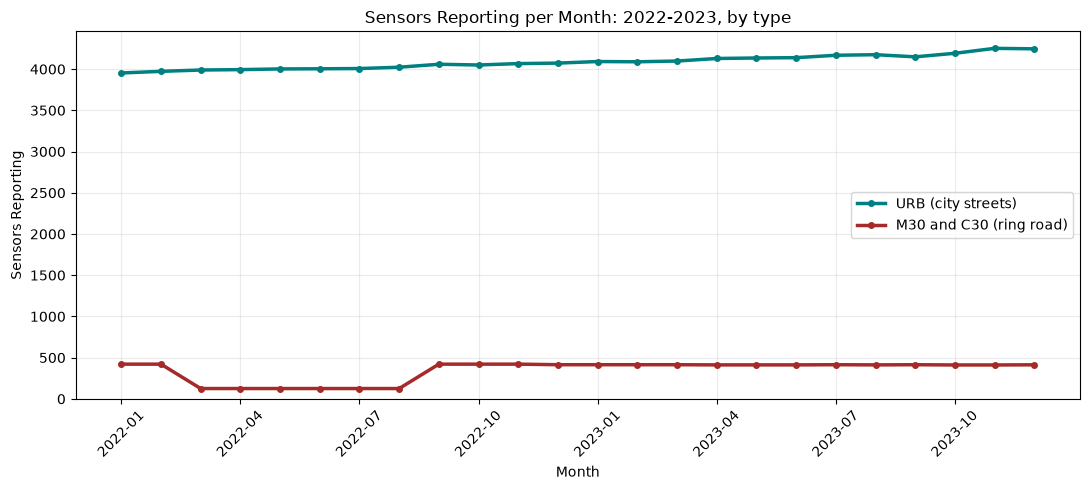

In [7]:
# Figure 3.2: sensors reporting per month, by type
by_type = (
    point_month_availability.with_columns(
        kind=pl.when(pl.col("tipo_elem") == URB).then(pl.lit("URB (city streets)"))
        .when(pl.col("tipo_elem").is_in(["M30", "C30"])).then(pl.lit("M30 and C30 (ring road)"))
        .otherwise(pl.lit("other"))  # 2 rows in two years
    )
    .filter(pl.col("kind") != "other")
    .group_by("month", "kind").agg(sensors=pl.len())
    .sort("month")
)
months = sorted(by_type["month"].unique().to_list())
fig, ax = plt.subplots(figsize=(11, 5))
for color, kind in zip(CATEGORY_COLORS, ["URB (city streets)", "M30 and C30 (ring road)"]):
    rows = by_type.filter(pl.col("kind") == kind)
    ax.plot([months.index(m) for m in rows["month"]], rows["sensors"], color=color, linewidth=LINE_WIDTH, marker="o", markersize=4, label=kind)
ax.set_xticks(range(0, len(months), 3), months[::3], rotation=45)
ax.set(xlabel="Month", ylabel="Sensors Reporting", ylim=(0, None))
ax.set_title(f"Sensors Reporting per Month: {EDA_PERIOD}, by type")
ax.legend()
style_axes(ax)
fig.tight_layout()
save_figure(fig, "fig-3-2-sensors-per-month.png")

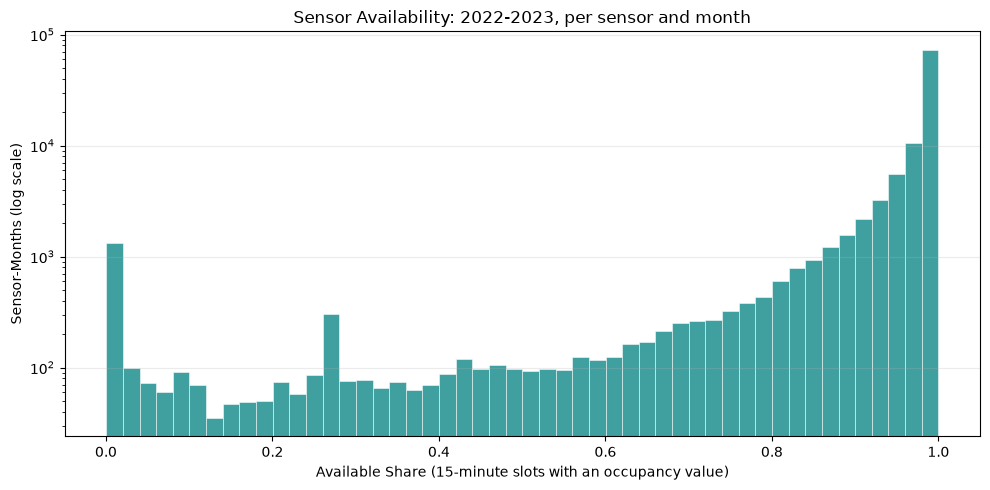

In [8]:
# Figure 3.3: availability per sensor and month
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(point_month_availability["available_share"], bins=50, color=CATEGORY_COLORS[0], alpha=0.75, edgecolor="white", linewidth=0.5)
ax.set_yscale("log")  # most sensor-months are near 1; the log scale keeps the long tail visible
ax.set(xlabel="Available Share (15-minute slots with an occupancy value)", ylabel="Sensor-Months (log scale)")
ax.set_title(f"Sensor Availability: {EDA_PERIOD}, per sensor and month")
style_axes(ax, "y")
fig.tight_layout()
save_figure(fig, "fig-3-3-availability.png")

Most sensors report in nearly every slot, with a small tail that rarely reports (Figure 3.3). The
ring-road total drops from March to August 2022 because M-30 sensors are missing, while urban sensors
grow gradually (Figure 3.2). Only urban sensors are therefore analysed, and district means use a
fixed sensor panel (Section 6).

## 4. Daylight-saving transitions
The spring change skips 02:00–03:00 and the autumn change repeats it. A normal Sunday is compared with
the 2022 transition days, and all four transition nights are then examined slot by slot, to see
whether broken rows can be recognised by sample count or only by timestamp.

In [9]:
DAYS_TO_COMPARE = {
    "normal Sunday": date(2022, 3, 20),
    "spring change": date(2022, 3, 27),
    "autumn change": date(2022, 10, 30),
}

for label, day in DAYS_TO_COMPARE.items():
    month_file = INTERIM_DATA_DIR / f"{day:%Y-%m}.parquet"
    per_point = (
        pl.read_parquet(month_file, columns=["id", "fecha", "tipo_elem", "periodo_integracion"])
        .filter(pl.col("tipo_elem") == URB, pl.col("fecha").dt.date() == day)
        .group_by("id")
        .agg(rows_that_day=pl.len(), samples_that_day=pl.col("periodo_integracion").sum())
    )
    print(
        f"{label:14} {day} rows: {per_point['rows_that_day'].mode().to_list()}"
        f" samples: {per_point['samples_that_day'].mode().to_list()} points: {per_point.height}"
    )

normal Sunday  2022-03-20 rows: [96] samples: [1440] points: 3940
spring change  2022-03-27 rows: [93] samples: [1378] points: 3946
autumn change  2022-10-30 rows: [96] samples: [1500] points: 3930


In [10]:
DST_DAYS = [date(2022, 3, 27), date(2022, 10, 30), date(2023, 3, 26), date(2023, 10, 29)]

for day in DST_DAYS:
    night_summary = (
        pl.read_parquet(
            INTERIM_DATA_DIR / f"{day:%Y-%m}.parquet",
            columns=["fecha", "tipo_elem", "periodo_integracion"],
        )
        .filter(
            pl.col("tipo_elem") == URB,
            pl.col("fecha").dt.date() == day,
            pl.col("fecha").dt.time().is_between(time(1, 30), time(3, 30)),
        )
        .group_by(pl.col("fecha").dt.time().alias("slot_end_time"))
        .agg(points=pl.len(), typical_samples=pl.col("periodo_integracion").mode().first())
        .sort("slot_end_time")
    )
    print(day)
    print(night_summary)

2022-03-27
shape: (6, 3)
┌───────────────┬────────┬─────────────────┐
│ slot_end_time ┆ points ┆ typical_samples │
│ ---           ┆ ---    ┆ ---             │
│ time          ┆ u32    ┆ i8              │
╞═══════════════╪════════╪═════════════════╡
│ 01:30:00      ┆ 3865   ┆ 15              │
│ 01:45:00      ┆ 3868   ┆ 15              │
│ 02:00:00      ┆ 3868   ┆ 14              │
│ 03:00:00      ┆ 3025   ┆ 1               │
│ 03:15:00      ┆ 3872   ┆ 15              │
│ 03:30:00      ┆ 3899   ┆ 15              │
└───────────────┴────────┴─────────────────┘
2022-10-30
shape: (9, 3)
┌───────────────┬────────┬─────────────────┐
│ slot_end_time ┆ points ┆ typical_samples │
│ ---           ┆ ---    ┆ ---             │
│ time          ┆ u32    ┆ i8              │
╞═══════════════╪════════╪═════════════════╡
│ 01:30:00      ┆ 3829   ┆ 15              │
│ 01:45:00      ┆ 3821   ┆ 15              │
│ 02:00:00      ┆ 3850   ┆ 16              │
│ 02:15:00      ┆ 3849   ┆ 30              │
│ 02:

In [11]:
points_by_samples = (
    pl.read_parquet(
        INTERIM_DATA_DIR / "2022-10.parquet",
        columns=["fecha", "tipo_elem", "periodo_integracion"],
    )
    .filter(
        pl.col("tipo_elem") == URB,
        pl.col("fecha") == datetime(2022, 10, 30, 2, 15),
    )
    ["periodo_integracion"]
    .value_counts(sort=True, name="points")
)
points_by_samples

periodo_integracion,points
i8,u32
30,2445
15,396
28,139
29,137
27,82
14,70
13,68
11,63
12,50


In [12]:
# points whose merged 02:15 row looks normal (at most 15 samples): a sample-count rule would keep them
points_by_samples.filter(pl.col("periodo_integracion") <= SAMPLES_FULL)["points"].sum()

878

The spring 03:00 row and the autumn 02:15–03:00 rows are broken (single samples or two slots merged),
and 878 merged 02:15 rows show 15 samples or fewer, so only a timestamp rule catches them.

**Decision.** The ten affected timestamps are removed (`DST_ROWS`). All later steps read rows through
`month_urb_rows` from `madrid_congestion.districts`: urban sensors only, without these rows.

In [13]:
# Check: DST_ROWS in config.py holds the rows decided above for the EDA years, all on the four clock-change nights.
# (DST_ROWS also lists the 2024 nights, added by the same pattern for the test year.)
eda_rows = [row for row in DST_ROWS if row.year in EDA_YEARS]
assert {row.date() for row in eda_rows} == set(DST_DAYS)
print(len(eda_rows), [f"{row:%Y-%m-%d %H:%M}" for row in eda_rows])

10 ['2022-03-27 03:00', '2022-10-30 02:15', '2022-10-30 02:30', '2022-10-30 02:45', '2022-10-30 03:00', '2023-03-26 03:00', '2023-10-29 02:15', '2023-10-29 02:30', '2023-10-29 02:45', '2023-10-29 03:00']


### Rows with more than 15 samples
A complete slot holds 15 samples, yet rows with more remain after the clock-change rows are removed.

In [14]:
# Rows with more than 15 samples in 2022, after the clock-change rows are removed: when and where?
rows_over_15 = pl.concat([
    month_urb_rows(month_label, ["id", "fecha", "periodo_integracion"]).filter(pl.col("periodo_integracion") > SAMPLES_FULL)
    for month_label in MONTHS_2022  # one month at a time
])
print(rows_over_15.height, "rows |", rows_over_15["id"].n_unique(), "sensors |", rows_over_15["fecha"].n_unique(), "timestamps")
print(rows_over_15["periodo_integracion"].value_counts(sort=True))  # how many samples
rows_over_15["fecha"].value_counts(sort=True).head(10)  # the timestamps with most such rows

3233 rows | 3233 sensors | 1 timestamps
shape: (1, 2)
┌─────────────────────┬───────┐
│ periodo_integracion ┆ count │
│ ---                 ┆ ---   │
│ i8                  ┆ u32   │
╞═════════════════════╪═══════╡
│ 16                  ┆ 3233  │
└─────────────────────┴───────┘


fecha,count
datetime[μs],u32
2022-10-30 02:00:00,3233


All 3,233 such rows have 16 samples and fall in the autumn 02:00 slot, one per sensor: a clock-change
artefact.

**Decision.** A valid reading has at most 15 samples (Section 6).

## 5. Minimum samples per reading (k)
A reading averaged from few one-minute samples can be dominated by one unusual minute, so a reading
counts only if it has at least k samples.

**Neighbour discrepancy.** For a row whose previous and next slots are complete: its occupancy minus
the mean of those two neighbours (pp). It is a proxy that mixes measurement noise with real traffic
change.

In [15]:
def month_neighbour_rows(month_label: str) -> pl.DataFrame:
    # URB rows of one month whose two neighbouring slots are complete, with occupancy_error.
    # one month of URB rows, sorted so each point's slots are in time order
    urb_rows = month_urb_rows(
        month_label, ["id", "fecha", "ocupacion", "periodo_integracion"]
    ).sort("id", "fecha")

    # attach each row's neighbouring slots and keep rows whose neighbours are complete
    with_neighbours = urb_rows.with_columns(
        prev_slot_end=pl.col("fecha").shift(1).over("id"),
        next_slot_end=pl.col("fecha").shift(-1).over("id"),
        prev_occupancy=pl.col("ocupacion").shift(1).over("id"),
        next_occupancy=pl.col("ocupacion").shift(-1).over("id"),
        prev_samples=pl.col("periodo_integracion").shift(1).over("id"),
        next_samples=pl.col("periodo_integracion").shift(-1).over("id"),
    )

    full_neighbour_rows = with_neighbours.filter(
        pl.col("prev_slot_end") == pl.col("fecha") - SLOT,  # the previous row is the slot just before
        pl.col("next_slot_end") == pl.col("fecha") + SLOT,  # the next row is the slot just after
        pl.col("prev_samples") == SAMPLES_FULL,
        pl.col("next_samples") == SAMPLES_FULL,
    )

    # the row's error: its occupancy minus the mean of its two neighbours
    return full_neighbour_rows.with_columns(
        neighbour_occupancy=(pl.col("prev_occupancy") + pl.col("next_occupancy"))/2,
    ).with_columns(
        occupancy_error=pl.col("ocupacion") - pl.col("neighbour_occupancy"),
    )


march = month_neighbour_rows(TRIAL_MONTH)  # March rows with two complete neighbours
march.height

8080988

In [16]:
def occupancy_error_by_samples(df: pl.DataFrame) -> pl.DataFrame:
    # Per sample count: rows, mean error, mean absolute error and median neighbour occupancy.
    return (
        df.group_by("periodo_integracion")
        .agg(
            rows=pl.len(),
            mean_error=pl.col("occupancy_error").mean().round(2),
            mean_abs_error=pl.col("occupancy_error").abs().mean().round(2),
            median_neighbour_occupancy=pl.col("neighbour_occupancy").median(),
        )
        .sort("periodo_integracion")
    )


occupancy_error_by_samples(march)

periodo_integracion,rows,mean_error,mean_abs_error,median_neighbour_occupancy
i8,u32,f64,f64,f64
1,189,1.93,3.63,0.5
2,290,2.67,4.02,0.5
3,559,2.52,3.86,0.5
4,1491,0.94,3.63,3.5
5,1143,1.43,2.78,0.5
6,1611,0.83,2.51,0.5
7,3511,0.44,2.44,1.5
8,5773,0.37,2.58,2.5
9,5912,0.52,2.47,1.5


In [17]:
NEIGHBOUR_OCCUPANCY_RANGE = (5, 20)  # moderate occupancy in %: compare only here (k rule, completed)

march_moderate_errors = occupancy_error_by_samples(
    march.filter(pl.col("neighbour_occupancy").is_between(*NEIGHBOUR_OCCUPANCY_RANGE))
)
march_moderate_errors

periodo_integracion,rows,mean_error,mean_abs_error,median_neighbour_occupancy
i8,u32,f64,f64,f64
1,22,12.75,20.43,8.0
2,32,11.19,17.22,7.75
3,77,12.59,16.41,6.5
4,520,1.4,4.97,7.5
5,135,5.06,9.95,7.5
6,222,1.96,7.46,7.0
7,635,0.38,5.2,7.5
8,1610,0.52,4.56,8.0
9,1018,1.0,5.86,8.0


Discrepancy grows with traffic, and short rows lie mostly on quiet roads: over all rows, 11–12-sample
rows look less noisy than 13–14-sample rows, but at 5–20% neighbour occupancy the order reverses.
Sample counts are therefore compared only at 5–20%.

**Criterion.** k is the smallest count from which every count is at most 1 pp (occupancy's reporting
step) noisier than a reference. The curve below uses nearly complete rows (13–14 samples); the choice
of reference is tested afterwards.

In [18]:
REFERENCE_BAND = (13, 14)  # nearly complete rows: the noise level we compare against (k rule)
TOLERANCE = 1.0  # occupancy percentage points (pp); our own choice (k rule)

### Noise curve for the training year
Monthly totals per sample count are added over 2022, so every row carries equal weight.

In [19]:
def month_error_totals(month_label: str) -> pl.DataFrame:
    # Per sample count: number of rows and sum of absolute occupancy errors, neighbours at 5-20%.
    return (
        month_neighbour_rows(month_label)
        .filter(pl.col("neighbour_occupancy").is_between(*NEIGHBOUR_OCCUPANCY_RANGE))
        .group_by("periodo_integracion")
        .agg(
            rows=pl.len(),
            abs_error_sum=pl.col("occupancy_error").abs().sum(),
        )
        .with_columns(month=pl.lit(month_label))  # which month the totals came from
        .sort("periodo_integracion")
    )


monthly_totals = []
for month_label in MONTHS_2022:  # one month at a time
    monthly_totals.append(month_error_totals(month_label))

year_totals = (
    pl.concat(monthly_totals)
    .group_by("periodo_integracion")
    .agg(
        rows=pl.col("rows").sum(),
        abs_error_sum=pl.col("abs_error_sum").sum(),
    )
    .sort("periodo_integracion")
)
year_totals

periodo_integracion,rows,abs_error_sum
i8,u32,f64
1,287,4716.0
2,511,7449.5
3,931,15554.5
4,2155,18001.0
5,2534,18995.0
6,4425,29239.0
7,6517,39864.5
8,11061,60015.0
9,11690,70693.0


In [20]:
reference_rows = year_totals.filter(pl.col("periodo_integracion").is_between(*REFERENCE_BAND))  # the 13- and 14-sample rows
reference_error = reference_rows["abs_error_sum"].sum() / reference_rows["rows"].sum()  # their mean error: total sum / total rows
print(round(reference_error, 2))  # show it, rounded for reading only

noise_curve = year_totals.with_columns(
    mean_abs_error=pl.col("abs_error_sum") / pl.col("rows"),
).with_columns(
    excess=pl.col("mean_abs_error") - reference_error,
)
noise_curve  # show the table

4.58


periodo_integracion,rows,abs_error_sum,mean_abs_error,excess
i8,u32,f64,f64,f64
1,287,4716.0,16.432056,11.847975
2,511,7449.5,14.578278,9.994197
3,931,15554.5,16.707304,12.123223
4,2155,18001.0,8.353132,3.769051
5,2534,18995.0,7.496054,2.911972
6,4425,29239.0,6.607684,2.023602
7,6517,39864.5,6.117002,1.53292
8,11061,60015.0,5.42582,0.841739
9,11690,70693.0,6.047305,1.463224


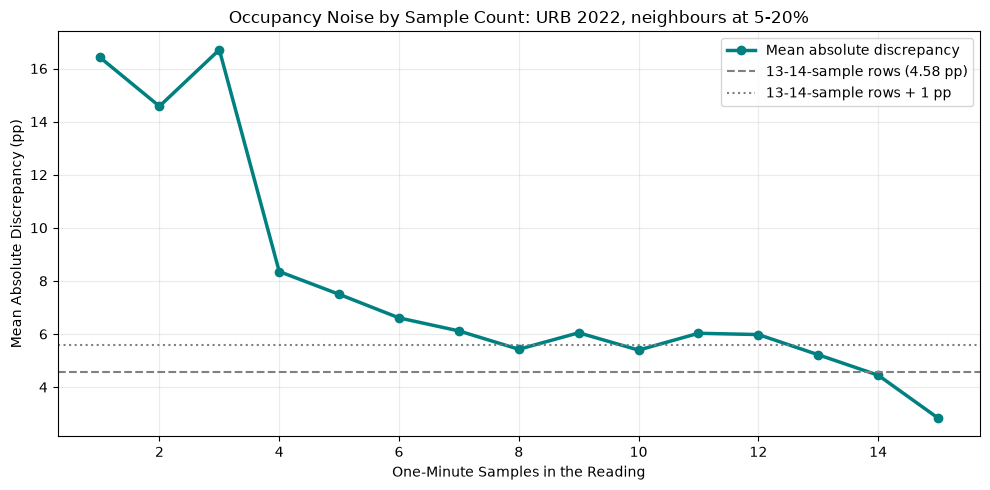

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(noise_curve["periodo_integracion"], noise_curve["mean_abs_error"], color=CATEGORY_COLORS[0],
        linewidth=LINE_WIDTH, marker="o", label="Mean absolute discrepancy")
ax.axhline(reference_error, color=REFERENCE, linewidth=REFERENCE_WIDTH, linestyle="--",
           label=f"13-14-sample rows ({reference_error:.2f} pp)")
ax.axhline(reference_error + TOLERANCE, color=REFERENCE, linewidth=REFERENCE_WIDTH, linestyle=":",
           label=f"13-14-sample rows + {TOLERANCE:g} pp")
ax.set(xlabel="One-Minute Samples in the Reading", ylabel="Mean Absolute Discrepancy (pp)")
ax.set_title("Occupancy Noise by Sample Count: URB 2022, neighbours at 5-20%")
ax.legend()
style_axes(ax)
fig.tight_layout()
plt.show()

### Cost of each k
The share of all 2022 urban rows each k would remove, set beside its noise excess.

In [22]:
def month_sample_counts(month_label: str) -> pl.DataFrame:
    # Number of URB rows per sample count in one month, without the clock-change rows.
    return (
        month_urb_rows(month_label, ["periodo_integracion"])
        .group_by("periodo_integracion")  # one group per sample count
        .agg(rows=pl.len())  # count the rows in each group
        .sort("periodo_integracion")  # sample counts from smallest to largest
    )


sample_count_tables = []  # one small table per month
for month_label in MONTHS_2022:  # the 12 months of 2022, one at a time
    sample_count_tables.append(month_sample_counts(month_label))

rows_by_samples_2022 = (
    pl.concat(sample_count_tables)  # the 12 tables stacked on top of each other
    .group_by("periodo_integracion")  # one group per sample count
    .agg(rows=pl.col("rows").sum())
    .sort("periodo_integracion")  # sample counts from smallest to largest
)
rows_by_samples_2022

periodo_integracion,rows
i8,u32
1,371322
2,443913
3,824061
4,1148138
5,858203
6,1114768
7,1225460
8,1498061
9,1675970


In [23]:
total_rows_2022 = rows_by_samples_2022["rows"].sum()  # all 2022 URB rows, without clock-change rows

k_cost = (
    rows_by_samples_2022.with_columns(
        rows_removed=pl.col("rows").cum_sum() - pl.col("rows"),  # rows with fewer samples than this count
    )
    .with_columns(
        removed_percent=(pl.col("rows_removed") / total_rows_2022 * 100).round(2),
    )
    .rename({"periodo_integracion": "k"})  # read each line as: "if k were this value"
    .select("k", "rows_removed", "removed_percent")  # only the columns we need
)

print(total_rows_2022)  # the base of the percent
k_cost

133474731


k,rows_removed,removed_percent
i8,u32,f64
1,0,0.0
2,371322,0.28
3,815235,0.61
4,1639296,1.23
5,2787434,2.09
6,3645637,2.73
7,4760405,3.57
8,5985865,4.48
9,7483926,5.61


In [24]:
k_table = (
    noise_curve.select(
        pl.col("periodo_integracion").alias("k"),  # the sample count, read as a possible k
        pl.col("excess").round(2),  # how much noisier rows at this count are than the 13-14 rows
    )
    .join(k_cost, on=pl.col("k"))
)
k_table

k,excess,rows_removed,removed_percent
i8,f64,u32,f64
1,11.85,0,0.0
2,9.99,371322,0.28
3,12.12,815235,0.61
4,3.77,1639296,1.23
5,2.91,2787434,2.09
6,2.02,3645637,2.73
7,1.53,4760405,3.57
8,0.84,5985865,4.48
9,1.46,7483926,5.61


Against the 13–14 reference the noise settles only from 13 samples (8 and 10 pass, but 9, 11 and 12
do not), so k would be 13. k = 16 is not a candidate (Section 4).

In [25]:
# First result: k under the 13-14 reference band (revised below by the reference band test).
curve = noise_curve.select("periodo_integracion", "excess").rows()  # (sample count, excess over the 13-14 rows)
k_with_band_13_14 = min(k for k, _ in curve if all(excess <= TOLERANCE for count, excess in curve if count >= k))
print(k_with_band_13_14)  # 13
k_cost.filter(pl.col("k") == k_with_band_13_14)  # what that k would cost in 2022

13


k,rows_removed,removed_percent
i8,u32,f64
13,16317087,12.22


### Reference rows
Complete rows are much less noisy than 13–14-sample rows. The gap may come from the missing minutes or
from noisier sensors being the ones that miss them. The test compares both within each sensor (at
least 20 rows of each kind, same sensor mix on both sides): d is the 13–14-sample rows' mean
discrepancy minus that of the same sensors' complete rows.

**Criterion** (fixed before the test): d ≤ 1 pp keeps the 13–14 reference; otherwise complete rows
become the reference.

In [26]:
REFERENCE_TEST_MIN_ROWS = 20  # a sensor is compared only with at least this many rows of each kind (our choice)


def month_band_errors(month_label: str) -> pl.DataFrame:
    # Per sensor, one month: rows and summed absolute error of its complete (15) and nearly complete (13-14)
    # rows, for rows whose neighbours are at moderate occupancy (as in the k test).
    return (
        month_neighbour_rows(month_label)
        .filter(
            pl.col("neighbour_occupancy").is_between(*NEIGHBOUR_OCCUPANCY_RANGE),  # moderate occupancy only
            pl.col("periodo_integracion").is_between(REFERENCE_BAND[0], SAMPLES_FULL),  # 13, 14 or 15 samples
        )
        .with_columns(complete=pl.col("periodo_integracion") == SAMPLES_FULL)  # True: 15 samples; False: 13-14
        .group_by("id", "complete")
        .agg(rows=pl.len(), abs_error_sum=pl.col("occupancy_error").abs().sum())
    )


band_errors = (
    pl.concat([month_band_errors(month_label) for month_label in MONTHS_2022])  # one month at a time
    .group_by("id", "complete")
    .agg(pl.col("rows").sum(), pl.col("abs_error_sum").sum())
)
complete_rows = band_errors.filter(pl.col("complete")).select(
    "id", rows_complete=pl.col("rows"), error_complete=pl.col("abs_error_sum") / pl.col("rows")
)
nearly_rows = band_errors.filter(~pl.col("complete")).select(
    "id", rows_nearly=pl.col("rows"), error_nearly=pl.col("abs_error_sum") / pl.col("rows")
)
same_sensors = complete_rows.join(nearly_rows, on="id", how="inner").filter(
    pl.col("rows_complete") >= REFERENCE_TEST_MIN_ROWS,
    pl.col("rows_nearly") >= REFERENCE_TEST_MIN_ROWS,
)

weight = pl.col("rows_nearly")  # same sensor mix on both sides: each sensor counts by its number of 13-14 rows
within = same_sensors.select(
    sensors=pl.len(),
    e_nearly=(pl.col("error_nearly") * weight).sum() / weight.sum(),  # 13-14-sample rows of these sensors
    e_complete=(pl.col("error_complete") * weight).sum() / weight.sum(),  # the same sensors' complete rows
)
within_gap = within.select(pl.col("e_nearly") - pl.col("e_complete")).item()  # d, the within-sensor gap (pp)

print(within)
print("pooled gap (all sensors):", round(reference_error - noise_curve.filter(pl.col("periodo_integracion") == SAMPLES_FULL)["mean_abs_error"].item(), 2), "pp")
print("within-sensor gap d:", round(within_gap, 2), "pp | criterion d <= TOLERANCE:", within_gap <= TOLERANCE)

# With complete rows as the reference (the test's outcome), k is the smallest count within TOLERANCE of them.
complete_error = noise_curve.filter(pl.col("periodo_integracion") == SAMPLES_FULL)["mean_abs_error"].item()  # 2.83 pp
excess_vs_complete = noise_curve.select("periodo_integracion", pl.col("mean_abs_error") - complete_error).rows()
k_with_complete = min(k for k, _ in excess_vs_complete if all(excess <= TOLERANCE for count, excess in excess_vs_complete if count >= k))
print("k with complete rows as reference:", k_with_complete)  # 15: the original decision, re-tested below
k_cost.filter(pl.col("k") == k_with_complete)  # what that k costs in 2022

shape: (1, 3)
┌─────────┬──────────┬────────────┐
│ sensors ┆ e_nearly ┆ e_complete │
│ ---     ┆ ---      ┆ ---        │
│ u32     ┆ f64      ┆ f64        │
╞═════════╪══════════╪════════════╡
│ 3298    ┆ 4.585342 ┆ 3.248466   │
└─────────┴──────────┴────────────┘
pooled gap (all sensors): 1.75 pp
within-sensor gap d: 1.34 pp | criterion d <= TOLERANCE: False
k with complete rows as reference: 15


k,rows_removed,removed_percent
i8,u32,f64
15,27459601,20.57


d = 1.34 pp exceeds the tolerance, so complete rows became the reference and k = 15 (removing 20.57%
of 2022 urban rows).

### Time-controlled follow-up
**Post-hoc follow-up.** The test above did not control time of day, although short rows cluster
around 06:00; this mattered once k = 15 left only 62% of 06:00 district slots valid. The follow-up
uses 2022 only, and its rule was fixed before its output was inspected.

**Matching.** 13- and 14-sample rows are tested separately against complete rows of the same sensor,
15-minute slot of day, weekday/weekend and 1-pp neighbour-occupancy bin, weighted to the candidates'
mix. A sensor × slot × day-type cell needs at least 20 complete rows.

**Decision rule.** A count passes if both its excess mean absolute discrepancy (ΔMAE) and its excess
signed discrepancy (|Δbias|) are ≤ 1 pp; bias counts because, unlike noise, it does not average out in
a district mean (this condition was added after an unmatched bias had been seen). k = 13 if 13 and 14
pass, 14 if only 14 passes, otherwise 15.

**Diagnostics** (not used for the decision): sensor-bootstrap 95% intervals; results by hour and for
06:00–09:59.

In [27]:
# Time-controlled follow-up (protocol above): totals per sensor x slot of day x day type x occupancy bin
# and sample count (13, 14 or 15), for rows with two complete neighbours whose mean is 5-20%.
CANDIDATE_COUNTS = (13, 14)  # tested separately, never pooled
FOLLOW_UP_MIN_COMPLETE = 20  # complete rows a sensor x slot-of-day x day-type cell needs to give a reference
CELL = ["id", "slot_of_day", "weekend"]  # the matching cell
TOTALS = [pl.col("rows").sum(), pl.col("abs_sum").sum(), pl.col("signed_sum").sum()]


def month_matched_totals(month_label: str) -> pl.DataFrame:
    # One month: rows and summed absolute and signed neighbour discrepancy per cell, bin and sample count.
    slot_start = pl.col("fecha") - SLOT  # fecha is the slot end
    return (
        month_neighbour_rows(month_label)
        .filter(
            pl.col("neighbour_occupancy").is_between(*NEIGHBOUR_OCCUPANCY_RANGE),  # 5-20%, both ends included
            pl.col("periodo_integracion").is_in([*CANDIDATE_COUNTS, SAMPLES_FULL]),  # 16-sample rows are not complete rows
        )
        .with_columns(
            slot_of_day=slot_start.dt.time(),  # e.g. 06:15
            weekend=slot_start.dt.weekday() >= 6,  # Saturday (6) or Sunday (7)
            occupancy_bin=pl.col("neighbour_occupancy").floor().clip(upper_bound=NEIGHBOUR_OCCUPANCY_RANGE[1] - 1).cast(pl.Int8),  # 5..19; 20.0 joins 19-20
        )
        .group_by(*CELL, "occupancy_bin", "periodo_integracion")
        .agg(rows=pl.len(), abs_sum=pl.col("occupancy_error").abs().sum(), signed_sum=pl.col("occupancy_error").sum())
    )


matched_totals = month_matched_totals(MONTHS_2022[0])  # running yearly totals, so only one month of rows is held at a time
for month_label in MONTHS_2022[1:]:
    matched_totals = (
        pl.concat([matched_totals, month_matched_totals(month_label)])
        .group_by(*CELL, "occupancy_bin", "periodo_integracion")
        .agg(TOTALS)
    )

print(matched_totals.height, "cell x bin x count totals")
matched_totals.group_by("periodo_integracion").agg(pl.col("rows").sum()).sort("periodo_integracion")  # rows per count

3470008 cell x bin x count totals


periodo_integracion,rows
i8,u32
13,133578
14,625099
15,24408680


In [28]:
complete = matched_totals.filter(pl.col("periodo_integracion") == SAMPLES_FULL)  # exactly 15 samples
eligible_cells = (
    complete.group_by(CELL).agg(complete_rows=pl.col("rows").sum())
    .filter(pl.col("complete_rows") >= FOLLOW_UP_MIN_COMPLETE)  # cells with a stable complete reference
)
complete_bins = complete.join(eligible_cells, on=CELL, how="semi").select(  # the reference per cell and bin
    *CELL, "occupancy_bin",
    complete_rows=pl.col("rows"),
    complete_mae=pl.col("abs_sum") / pl.col("rows"),
    complete_bias=pl.col("signed_sum") / pl.col("rows"),
)


def matched_rows(m: int) -> pl.DataFrame:
    # The m-sample totals with the complete reference of the same cell and occupancy bin.
    return matched_totals.filter(pl.col("periodo_integracion") == m).join(complete_bins, on=[*CELL, "occupancy_bin"], how="inner")


candidate_weight = pl.col("rows")  # each cell and bin counts by its number of candidate rows
SUMMARY = [
    candidate_weight.sum().alias("rows"),
    pl.col("complete_rows").sum().alias("complete_reference_rows"),
    (pl.col("abs_sum").sum() / candidate_weight.sum()).alias("incomplete_mae"),
    ((pl.col("complete_mae") * candidate_weight).sum() / candidate_weight.sum()).alias("complete_mae"),
    (pl.col("signed_sum").sum() / candidate_weight.sum()).alias("incomplete_bias"),
    ((pl.col("complete_bias") * candidate_weight).sum() / candidate_weight.sum()).alias("complete_bias"),
]
DELTAS = [
    (pl.col("incomplete_mae") - pl.col("complete_mae")).alias("delta_mae"),  # ΔMAE (pp)
    (pl.col("incomplete_bias") - pl.col("complete_bias")).alias("delta_bias"),  # Δbias (pp)
]

coverage = []
for m in CANDIDATE_COUNTS:
    candidate_rows = matched_totals.filter(pl.col("periodo_integracion") == m)
    in_cells = candidate_rows.join(eligible_cells, on=CELL, how="semi")
    matched = matched_rows(m)
    eligible_count = int(candidate_rows["rows"].sum())  # all m-sample rows with complete neighbours at 5-20%
    matched_count = int(matched["rows"].sum())  # ... in a reference cell and in a bin that has complete rows
    coverage.append({
        "candidate": m,
        "eligible_rows": eligible_count,
        "rows_in_reference_cells": int(in_cells["rows"].sum()),  # ... in a cell with at least 20 complete rows
        "rows_matched": matched_count,
        "matched_percent": round(100 * matched_count / eligible_count, 1),
        "cells": matched.select(CELL).unique().height,
        "sensors": matched["id"].n_unique(),
    })
print("eligible reference cells:", eligible_cells.height)
with pl.Config(tbl_cols=-1):
    print(pl.DataFrame(coverage))

results = (
    pl.concat([matched_rows(m).select(SUMMARY).with_columns(candidate=pl.lit(m, dtype=pl.Int8)) for m in CANDIDATE_COUNTS])
    .with_columns(DELTAS)
    .with_columns(mae_pass=pl.col("delta_mae") <= TOLERANCE, bias_pass=pl.col("delta_bias").abs() <= TOLERANCE)
    .with_columns(overall_pass=pl.col("mae_pass") & pl.col("bias_pass"))
    .select("candidate", pl.exclude("candidate"))
)
passes = dict(zip(results["candidate"].to_list(), results["overall_pass"].to_list()))
k_final = 13 if passes[13] and passes[14] else 14 if passes[14] else SAMPLES_FULL  # the frozen rule

with pl.Config(tbl_cols=-1, float_precision=3):
    print(results)
print(f"\nFINAL k = {k_final}")

eligible reference cells: 236010
shape: (2, 7)
┌───────────┬───────────────┬──────────────────┬──────────────┬─────────────────┬────────┬─────────┐
│ candidate ┆ eligible_rows ┆ rows_in_referenc ┆ rows_matched ┆ matched_percent ┆ cells  ┆ sensors │
│ ---       ┆ ---           ┆ e_cells          ┆ ---          ┆ ---             ┆ ---    ┆ ---     │
│ i64       ┆ i64           ┆ ---              ┆ i64          ┆ f64             ┆ i64    ┆ i64     │
│           ┆               ┆ i64              ┆              ┆                 ┆        ┆         │
╞═══════════╪═══════════════╪══════════════════╪══════════════╪═════════════════╪════════╪═════════╡
│ 13        ┆ 133578        ┆ 104221           ┆ 100014       ┆ 74.9            ┆ 59371  ┆ 3228    │
│ 14        ┆ 625099        ┆ 547374           ┆ 531558       ┆ 85.0            ┆ 150162 ┆ 3443    │
└───────────┴───────────────┴──────────────────┴──────────────┴─────────────────┴────────┴─────────┘
shape: (2, 12)
┌────────┬────────┬────────┬─

In [29]:
# Uncertainty (descriptive, not used for the decision): 1,000 bootstrap resamples of sensors.
BOOTSTRAP_DRAWS = 1000

intervals = []
for m in CANDIDATE_COUNTS:
    per_sensor = matched_rows(m).group_by("id").agg(  # each sensor's sums, so a resample adds them up
        n=candidate_weight.sum(),
        abs_incomplete=pl.col("abs_sum").sum(),
        abs_complete=(pl.col("complete_mae") * candidate_weight).sum(),
        signed_incomplete=pl.col("signed_sum").sum(),
        signed_complete=(pl.col("complete_bias") * candidate_weight).sum(),
    ).sort("id")  # group_by returns groups in random order; sorting makes each seed draw the same sensors
    draws = []
    for seed in range(1, BOOTSTRAP_DRAWS + 1):
        s = per_sensor.sample(fraction=1.0, with_replacement=True, seed=seed).sum()  # sensors drawn with replacement
        draws.append({
            "delta_mae": ((s["abs_incomplete"] - s["abs_complete"]) / s["n"]).item(),
            "delta_bias": ((s["signed_incomplete"] - s["signed_complete"]) / s["n"]).item(),
        })
    draws = pl.DataFrame(draws)
    for statistic in ("delta_mae", "delta_bias"):
        intervals.append({
            "candidate": m, "statistic": statistic,
            "low_2.5": draws[statistic].quantile(0.025), "high_97.5": draws[statistic].quantile(0.975),
        })
with pl.Config(float_precision=3):
    print(pl.DataFrame(intervals))

shape: (4, 4)
┌───────────┬────────────┬─────────┬───────────┐
│ candidate ┆ statistic  ┆ low_2.5 ┆ high_97.5 │
│ ---       ┆ ---        ┆ ---     ┆ ---       │
│ i64       ┆ str        ┆ f64     ┆ f64       │
╞═══════════╪════════════╪═════════╪═══════════╡
│ 13        ┆ delta_mae  ┆ 1.382   ┆ 1.849     │
│ 13        ┆ delta_bias ┆ 1.358   ┆ 2.018     │
│ 14        ┆ delta_mae  ┆ 1.035   ┆ 1.377     │
│ 14        ┆ delta_bias ┆ 1.320   ┆ 1.809     │
└───────────┴────────────┴─────────┴───────────┘


In [30]:
# Diagnostics (not used for the decision): the matched differences by hour of the slot start and for 06:00-09:59.
hour = pl.col("slot_of_day").dt.hour()
by_hour = (
    pl.concat([
        matched_rows(m).group_by(hour.alias("hour")).agg(SUMMARY).with_columns(candidate=pl.lit(m, dtype=pl.Int8))
        for m in CANDIDATE_COUNTS
    ])
    .with_columns(DELTAS)
    .select("candidate", "hour", "rows", "delta_mae", "delta_bias")
    .sort("candidate", "hour")
)
morning = (
    pl.concat([
        matched_rows(m).filter(hour.is_between(6, 9)).select(SUMMARY).with_columns(candidate=pl.lit(m, dtype=pl.Int8))
        for m in CANDIDATE_COUNTS
    ])
    .with_columns(DELTAS)
    .select("candidate", pl.exclude("candidate"))
)
with pl.Config(tbl_rows=50, tbl_cols=-1, float_precision=3):
    print(by_hour)
    print("06:00-09:59")
    print(morning)

assert k_final == MIN_SAMPLES, f"the follow-up selects k = {k_final}: set MIN_SAMPLES = {k_final} in config.py, then Restart and Run All"

shape: (48, 5)
┌───────────┬──────┬───────┬───────────┬────────────┐
│ candidate ┆ hour ┆ rows  ┆ delta_mae ┆ delta_bias │
│ ---       ┆ ---  ┆ ---   ┆ ---       ┆ ---        │
│ i8        ┆ i8   ┆ u32   ┆ f64       ┆ f64        │
╞═══════════╪══════╪═══════╪═══════════╪════════════╡
│ 13        ┆ 0    ┆ 1553  ┆ 0.874     ┆ 0.582      │
│ 13        ┆ 1    ┆ 717   ┆ 1.761     ┆ 1.207      │
│ 13        ┆ 2    ┆ 940   ┆ 0.560     ┆ 0.185      │
│ 13        ┆ 3    ┆ 1123  ┆ 0.436     ┆ 0.281      │
│ 13        ┆ 4    ┆ 443   ┆ 1.816     ┆ 1.523      │
│ 13        ┆ 5    ┆ 433   ┆ 0.925     ┆ 0.759      │
│ 13        ┆ 6    ┆ 1395  ┆ 0.558     ┆ -0.390     │
│ 13        ┆ 7    ┆ 2710  ┆ 1.458     ┆ 1.166      │
│ 13        ┆ 8    ┆ 5299  ┆ 1.535     ┆ 1.500      │
│ 13        ┆ 9    ┆ 5735  ┆ 1.920     ┆ 2.130      │
│ 13        ┆ 10   ┆ 5822  ┆ 1.785     ┆ 2.200      │
│ 13        ┆ 11   ┆ 9351  ┆ 1.240     ┆ 1.496      │
│ 13        ┆ 12   ┆ 7032  ┆ 1.811     ┆ 2.207      │
│ 13        ┆

Both counts fail both conditions, with every bootstrap interval above 1 pp; the excess is mainly a
positive bias of incomplete readings. In the 06:00 hour both counts are within tolerance, so the
timing explanation is not supported.

**Decision.** k = 15: only complete readings count (`MIN_SAMPLES`). Limitations: the discrepancy is a
proxy, it covers only isolated short rows, and 15–25% of candidate rows could not be matched.

## 6. Fixed sensor panel
District values are means over a fixed set of sensors chosen on 2022, so they do not shift when
sensors drop out (Section 3).

### Valid readings and sensor availability
A **valid reading** comes from an urban sensor, outside the clock-change rows, with k to 15 samples,
occupancy and flow present, and flow ≤ 5,000 vehicles per hour (Section 7). A sensor's availability is
its share of valid readings over the 2022 slots with data; it enters the panel if availability is at
least a cut-off c.

In [31]:
# A valid reading uses VALID_READING from districts.py: k to 15 samples, occupancy and flow present,
# flow at most MAX_FLOW (Section 7).


def month_valid_readings(month_label: str) -> pl.DataFrame:
    # Per URB measuring point: number of valid readings in one month.
    return (
        month_urb_rows(month_label, ["id", "intensidad", "ocupacion", "periodo_integracion"])
        .group_by("id")  # one group per measuring point
        .agg(valid_readings=VALID_READING.sum())  # True = 1, False = 0, so the sum counts the valid rows
        .sort("id")  # measuring points in id order
    )


def month_slots(month_label: str) -> int:
    # Number of 15-min slots in one month that have URB rows, without the clock-change rows.
    return month_urb_rows(month_label, ["fecha"])["fecha"].n_unique()  # count each slot once


valid_tables = []  # one table per month: valid readings per measuring point
year_slots = 0  # running total of 2022 slots
for month_label in MONTHS_2022:
    valid_tables.append(month_valid_readings(month_label))
    year_slots += month_slots(month_label)

point_shares_2022 = (
    pl.concat(valid_tables)  # the 12 tables stacked
    .group_by("id")  # one group per measuring point
    .agg(valid_readings=pl.col("valid_readings").sum())  # valid readings over the whole year
    .with_columns(valid_share=pl.col("valid_readings") / year_slots)  # share of all 2022 slots
    .sort("id")  # measuring points in id order
)

print(year_slots)  # all 2022 slots
print(point_shares_2022.height)  # all URB measuring points that reported in 2022
point_shares_2022["valid_share"].describe()

35032
4122


statistic,value
str,f64
"""count""",4122.0
"""null_count""",0.0
"""mean""",0.73413
"""std""",0.219263
"""min""",0.0
"""25%""",0.615066
"""50%""",0.799526
"""75%""",0.910196
"""max""",0.981246


### Sensor-to-district mapping
The number of sensors kept falls steadily with c, without a natural break (Figure 3.4a), so c is tied
to district coverage instead. Districts come from the December 2021 and December 2022 location files
combined (December 2022 wins where they differ).

In [32]:
locations_2021, locations_2022 = read_locations("2021-12"), read_locations("2022-12")
point_districts = combine_locations(locations_2022, locations_2021)  # union; December 2022 wins where both list an id

print(locations_2021.height, locations_2022.height, point_districts.height)  # rows per file and in the union
print(point_districts["id"].n_unique() == point_districts.height)  # every id exactly once?
print(point_districts["distrito"].null_count())  # measuring points without a district

4571 4690 4707
True
5


In [33]:
matched = point_shares_2022.join(point_districts, on="id", how="inner")  # keep only measuring points found in both tables
with_district = matched.filter(pl.col("distrito").is_not_null())  # drop the ones whose distrito is null

print(point_shares_2022.height, matched.height, with_district.height)  # before, after the join, after the null filter
print(with_district["distrito"].n_unique())  # number of districts
point_shares_2022.join(point_districts, on="id", how="anti")  # the measuring points the join dropped: who are they?

4122 4120 4115
21


id,valid_readings,valid_share
i32,u32,f64
479309,0,0.0
50335653,0,0.0


Two unmatched ids have no valid reading and five sensors have no district; both are dropped. All 21
districts remain.

### Panel cut-off
A district is studied only if it has a minimum number of panel sensors. c is the highest value that
keeps every district eligible without a cut-off, so no district is lost. The minimum is itself
estimated on panel sensors, so a provisional minimum of 20 is used first and c is re-derived once
with the estimated minimum.

In [34]:
cutoffs = list(PANEL_CUTOFFS)  # c from 0.50 to 1.00 in steps of 0.01
MIN_DISTRICT_POINTS = 20  # a district needs at least this many panel points (District eligibility confirmed)


def points_per_district(c: float) -> pl.DataFrame:
    # Panel points per district at cut-off c, smallest districts first.
    return (
        with_district.filter(pl.col("valid_share") >= c)  # measuring points that pass cut-off c
        .group_by("distrito")  # one group per district
        .agg(points=pl.len())  # panel points per district
        .sort("points")  # smallest number of points first
    )


def eligible_districts(c: float) -> int:
    # Number of districts with at least MIN_DISTRICT_POINTS measuring points whose share is at least c.
    return points_per_district(c).filter(pl.col("points") >= MIN_DISTRICT_POINTS).height


districts_without_cutoff = eligible_districts(0.0)  # c = 0: every measuring point counts
districts_per_cutoff = [eligible_districts(c) for c in cutoffs]  # one count per c, 0.50 to 1.00
chosen_c = max(c for c, districts in zip(cutoffs, districts_per_cutoff) if districts == districts_without_cutoff)  # the rule

print(districts_without_cutoff)  # districts eligible with no cut-off
print(chosen_c)  # the chosen c

cutoff_table = pl.DataFrame(
    {
        "c": cutoffs,
        "points": [points_per_district(c)["points"].sum() for c in cutoffs],  # panel points that have a district
        "eligible_districts": districts_per_cutoff,
    }
)
cutoff_table.slice(cutoffs.index(chosen_c) - 3, 7)  # the evidence: the cut-offs around the chosen c

21
0.69


c,points,eligible_districts
f64,i64,i64
0.66,2886,21
0.67,2838,21
0.68,2774,21
0.69,2719,21
0.7,2661,20
0.71,2609,20
0.72,2554,20


In [35]:
panel_sizes = points_per_district(chosen_c)  # panel points per district at the chosen c
print(panel_sizes.head(5))  # the five smallest districts
print(points_per_district(chosen_c + 0.01).head(5))  # one step stricter: who falls below MIN_DISTRICT_POINTS?

panel_points = with_district.filter(pl.col("valid_share") >= chosen_c).select("id", "distrito")  # the panel: fixed 2022 list
print(panel_points.height, panel_sizes.height, panel_sizes["points"].min())  # panel points, districts, smallest district
panel_sizes.sort("points", descending=True).head(3)  # the three largest districts (the test districts below)

shape: (5, 2)
┌──────────┬────────┐
│ distrito ┆ points │
│ ---      ┆ ---    │
│ i64      ┆ u32    │
╞══════════╪════════╡
│ 21       ┆ 21     │
│ 19       ┆ 28     │
│ 18       ┆ 37     │
│ 14       ┆ 65     │
│ 2        ┆ 67     │
└──────────┴────────┘
shape: (5, 2)
┌──────────┬────────┐
│ distrito ┆ points │
│ ---      ┆ ---    │
│ i64      ┆ u32    │
╞══════════╪════════╡
│ 21       ┆ 19     │
│ 19       ┆ 28     │
│ 18       ┆ 37     │
│ 14       ┆ 65     │
│ 2        ┆ 65     │
└──────────┴────────┘
2719 21 21


distrito,points
i64,u32
11,297
15,278
8,272


### Minimum number of sensors per district
The district with the fewest sensors fixes c, so the minimum matters. It is estimated by subsampling
the three largest districts of the provisional panel over all of 2022: E(n) is the mean absolute gap
between M(t), the mean of n random panel sensors, and F(t), the all-sensor mean, over busy slots (F(t)
of 5–20%) and 20 draws per n.

In [36]:
def month_panel_readings(month_label: str, district: int) -> pl.DataFrame:
    # Valid readings (slot, measuring point, occupancy) of one district's panel points in one month.
    district_panel = panel_points.filter(pl.col("distrito") == district)  # this district's panel points
    return (
        month_urb_rows(month_label, ["id", "fecha", "intensidad", "ocupacion", "periodo_integracion"])
        .join(district_panel, on="id", how="semi")  # keep only this district's panel points, add no columns
        .filter(VALID_READING)  # valid readings only (k rule)
        .select("fecha", "id", "ocupacion")  # only what the test needs
    )


def subsample_error(readings: pl.DataFrame, full_mean: pl.DataFrame, n: int, seed: int) -> float:
    # Mean absolute gap (pp) between the mean of n random panel points and the full mean, over all slots.
    chosen_ids = readings["id"].unique().sort().sample(n, seed=seed).to_frame()  # n measuring points at random, reproducible
    sample_mean = (
        readings.join(chosen_ids, on="id", how="semi")  # only the chosen measuring points
        .group_by("fecha")  # one group per slot
        .agg(sample_mean=pl.col("ocupacion").mean())  # their mean occupancy in this slot
    )
    return (
        sample_mean.join(full_mean, on="fecha", how="inner")  # line the two means up slot by slot
        .select((pl.col("sample_mean") - pl.col("full_mean")).abs().mean())  # the gap between the two mean columns
        .item()  # one number
    )

In [37]:
TEST_DISTRICTS = panel_sizes.sort("points", descending=True).head(3)["distrito"].to_list()  # the three largest districts of the provisional panel
YEAR_N_VALUES = [10, 20, 30, 40, 50, 75, 100, 150]  # n to test; values near a district's panel size understate the gap
DRAWS = 20  # random draws per n


def year_gap_curve(district: int) -> pl.DataFrame:
    # E(n) for one district on the whole training year, busy slots only.
    readings = pl.concat([month_panel_readings(month_label, district) for month_label in MONTHS_2022])  # one month at a time
    full_mean = readings.group_by("fecha").agg(full_mean=pl.col("ocupacion").mean())  # F(t) per slot
    busy_full_mean = full_mean.filter(pl.col("full_mean").is_between(*NEIGHBOUR_OCCUPANCY_RANGE))
    mean_gaps = [
        sum(subsample_error(readings, busy_full_mean, n=n, seed=seed) for seed in range(1, DRAWS + 1)) / DRAWS  # E(n)
        for n in YEAR_N_VALUES
    ]
    return pl.DataFrame({"n": YEAR_N_VALUES, "mean_gap": mean_gaps}).with_columns(
        distrito=pl.lit(district),  # which district
        busy_slots=pl.lit(busy_full_mean.height),  # T for this district
    )


year_gap_curves = pl.concat([year_gap_curve(district) for district in TEST_DISTRICTS])  # the three test districts

with pl.Config(tbl_rows=30):  # show all 24 rows (3 districts × 8 values of n)
    print(year_gap_curves)

shape: (24, 4)
┌─────┬──────────┬──────────┬────────────┐
│ n   ┆ mean_gap ┆ distrito ┆ busy_slots │
│ --- ┆ ---      ┆ ---      ┆ ---        │
│ i64 ┆ f64      ┆ i32      ┆ i32        │
╞═════╪══════════╪══════════╪════════════╡
│ 10  ┆ 2.202982 ┆ 11       ┆ 18033      │
│ 20  ┆ 1.493163 ┆ 11       ┆ 18033      │
│ 30  ┆ 1.590528 ┆ 11       ┆ 18033      │
│ 40  ┆ 1.423458 ┆ 11       ┆ 18033      │
│ 50  ┆ 1.152147 ┆ 11       ┆ 18033      │
│ 75  ┆ 0.884955 ┆ 11       ┆ 18033      │
│ 100 ┆ 0.644368 ┆ 11       ┆ 18033      │
│ 150 ┆ 0.435129 ┆ 11       ┆ 18033      │
│ 10  ┆ 2.088117 ┆ 15       ┆ 14111      │
│ 20  ┆ 2.0933   ┆ 15       ┆ 14111      │
│ 30  ┆ 1.567631 ┆ 15       ┆ 14111      │
│ 40  ┆ 1.352107 ┆ 15       ┆ 14111      │
│ 50  ┆ 1.216359 ┆ 15       ┆ 14111      │
│ 75  ┆ 0.808546 ┆ 15       ┆ 14111      │
│ 100 ┆ 0.742544 ┆ 15       ┆ 14111      │
│ 150 ┆ 0.465227 ┆ 15       ┆ 14111      │
│ 10  ┆ 2.756098 ┆ 8        ┆ 13510      │
│ 20  ┆ 2.033497 ┆ 8        ┆ 13510    

A constant offset between M(t) and F(t) shifts a district's series and its high-occupancy threshold
(a percentile of the same series) together, leaving onset times unchanged. The minimum is therefore judged on the variation around the
offset: W(n), the mean of |d(t) − b| over 20 draws, where d(t) = M(t) − F(t) and b, the offset, is the
mean of d(t).

**Criterion** (adopted after E(n) was seen, before W(n) was computed): the smallest tested n with
W(n) ≤ 1 pp in all three districts.

In [38]:
def subsample_wobble(readings: pl.DataFrame, full_mean: pl.DataFrame, n: int, seed: int) -> float:
    # Wobble size (pp) of one draw: the gap between n random panel sensors and the all-sensor mean,
    # after removing the draw's constant offset.
    chosen_ids = readings["id"].unique().sort().sample(n, seed=seed).to_frame()  # n sensors at random, reproducible
    sample_mean = (
        readings.join(chosen_ids, on="id", how="semi")  # only the drawn sensors
        .group_by("fecha")  # one group per slot
        .agg(sample_mean=pl.col("ocupacion").mean())  # M(t), the n-sensor mean in this slot
    )
    difference = pl.col("difference")  # d(t), the difference per slot
    offset = difference.mean()  # b, the constant offset: the mean of the differences
    return (
        sample_mean.join(full_mean, on="fecha", how="inner")  # line M(t) and F(t) up slot by slot
        .select(difference=pl.col("sample_mean") - pl.col("full_mean"))
        .select((difference - offset).abs().mean())  # the wobble size: the mean of |difference - offset|
        .item()  # one number
    )


def year_wobble_curve(district: int) -> pl.DataFrame:
    # W(n), the wobble at n, for one district on the whole training year, busy slots only.
    readings = pl.concat([month_panel_readings(month_label, district) for month_label in MONTHS_2022])  # one month at a time
    full_mean = readings.group_by("fecha").agg(full_mean=pl.col("ocupacion").mean())  # F(t), the all-sensor mean per slot
    busy_full_mean = full_mean.filter(pl.col("full_mean").is_between(*NEIGHBOUR_OCCUPANCY_RANGE))  # slots with F(t) 5-20%
    mean_wobbles = [
        sum(subsample_wobble(readings, busy_full_mean, n=n, seed=seed) for seed in range(1, DRAWS + 1)) / DRAWS  # W(n), the wobble at n
        for n in YEAR_N_VALUES
    ]
    return pl.DataFrame({"n": YEAR_N_VALUES, "mean_wobble": mean_wobbles}).with_columns(distrito=pl.lit(district))


year_wobble_curves = pl.concat([year_wobble_curve(district) for district in TEST_DISTRICTS])  # the three test districts
with pl.Config(tbl_rows=30):  # show all 24 rows
    print(year_wobble_curves)

shape: (24, 3)
┌─────┬─────────────┬──────────┐
│ n   ┆ mean_wobble ┆ distrito │
│ --- ┆ ---         ┆ ---      │
│ i64 ┆ f64         ┆ i32      │
╞═════╪═════════════╪══════════╡
│ 10  ┆ 1.638385    ┆ 11       │
│ 20  ┆ 1.00205     ┆ 11       │
│ 30  ┆ 0.830469    ┆ 11       │
│ 40  ┆ 0.73196     ┆ 11       │
│ 50  ┆ 0.650606    ┆ 11       │
│ 75  ┆ 0.508951    ┆ 11       │
│ 100 ┆ 0.417378    ┆ 11       │
│ 150 ┆ 0.295762    ┆ 11       │
│ 10  ┆ 1.326128    ┆ 15       │
│ 20  ┆ 1.128049    ┆ 15       │
│ 30  ┆ 0.90731     ┆ 15       │
│ 40  ┆ 0.768272    ┆ 15       │
│ 50  ┆ 0.693486    ┆ 15       │
│ 75  ┆ 0.53109     ┆ 15       │
│ 100 ┆ 0.433856    ┆ 15       │
│ 150 ┆ 0.287789    ┆ 15       │
│ 10  ┆ 1.461594    ┆ 8        │
│ 20  ┆ 1.231796    ┆ 8        │
│ 30  ┆ 0.949329    ┆ 8        │
│ 40  ┆ 0.817103    ┆ 8        │
│ 50  ┆ 0.718563    ┆ 8        │
│ 75  ┆ 0.586106    ┆ 8        │
│ 100 ┆ 0.462185    ┆ 8        │
│ 150 ┆ 0.310966    ┆ 8        │
└─────┴─────────────┴───────

In [39]:
# The wobble criterion: the smallest tested n at which W(n), the wobble at n, is at most TOLERANCE,
# required in all three test districts (decision log: District minimum, wobble criterion).
both_measures = year_gap_curves.join(year_wobble_curves, on=["distrito", "n"])  # gap and wobble side by side
n_min_per_district = (
    both_measures.filter(pl.col("mean_wobble") <= TOLERANCE)  # tested n that meet the criterion
    .group_by("distrito")
    .agg(n_min=pl.col("n").min())  # the smallest such n in each district
    .sort("distrito")
)
assert n_min_per_district.height == len(TEST_DISTRICTS), "a district never reaches the tolerance"
# must hold in all three districts, so the largest; declared int so later cells see an int, not any value
district_minimum: int = n_min_per_district.select(pl.col("n_min").max()).item()

assert district_minimum == DISTRICT_MINIMUM, f"set DISTRICT_MINIMUM = {district_minimum} in config.py"
print(n_min_per_district)
print("district minimum from the wobble criterion:", district_minimum)
with pl.Config(tbl_rows=30):  # all 24 rows
    print(both_measures.sort("distrito", "n"))

shape: (3, 2)
┌──────────┬───────┐
│ distrito ┆ n_min │
│ ---      ┆ ---   │
│ i32      ┆ i64   │
╞══════════╪═══════╡
│ 8        ┆ 30    │
│ 11       ┆ 30    │
│ 15       ┆ 30    │
└──────────┴───────┘
district minimum from the wobble criterion: 30
shape: (24, 5)
┌─────┬──────────┬──────────┬────────────┬─────────────┐
│ n   ┆ mean_gap ┆ distrito ┆ busy_slots ┆ mean_wobble │
│ --- ┆ ---      ┆ ---      ┆ ---        ┆ ---         │
│ i64 ┆ f64      ┆ i32      ┆ i32        ┆ f64         │
╞═════╪══════════╪══════════╪════════════╪═════════════╡
│ 10  ┆ 2.756098 ┆ 8        ┆ 13510      ┆ 1.461594    │
│ 20  ┆ 2.033497 ┆ 8        ┆ 13510      ┆ 1.231796    │
│ 30  ┆ 1.474759 ┆ 8        ┆ 13510      ┆ 0.949329    │
│ 40  ┆ 1.346448 ┆ 8        ┆ 13510      ┆ 0.817103    │
│ 50  ┆ 1.273451 ┆ 8        ┆ 13510      ┆ 0.718563    │
│ 75  ┆ 1.14272  ┆ 8        ┆ 13510      ┆ 0.586106    │
│ 100 ┆ 0.938019 ┆ 8        ┆ 13510      ┆ 0.462185    │
│ 150 ┆ 0.67666  ┆ 8        ┆ 13510      ┆ 0.310966

Removing the offset lowers the gap at every n (Figure 3.4b).

**Decision.** The district minimum is `district_minimum` (printed above; `DISTRICT_MINIMUM` in
`config.py`).

### Cost of k for the panel
The provisional panel is rebuilt without the k rule, to show how many sensors and districts k costs.

In [40]:
VALID_WITHOUT_K = VALUES_PRESENT & FLOW_PLAUSIBLE  # valid reading if k were not applied


def month_valid_readings_without_k(month_label: str) -> pl.DataFrame:
    # Per sensor: readings in one month that would be valid without the k rule.
    return (
        month_urb_rows(month_label, ["id", "intensidad", "ocupacion"])
        .group_by("id")
        .agg(valid_readings=VALID_WITHOUT_K.sum())
    )


shares_without_k = (
    pl.concat([month_valid_readings_without_k(month_label) for month_label in MONTHS_2022])  # one month at a time
    .group_by("id")
    .agg(valid_readings=pl.col("valid_readings").sum())
    .with_columns(valid_share=pl.col("valid_readings") / year_slots)  # same denominator as with k
    .join(point_districts, on="id", how="inner")  # same district mapping
    .filter(pl.col("distrito").is_not_null())
)

for label, shares in [(f"with k = {MIN_SAMPLES}", with_district), ("without k", shares_without_k)]:
    panel = shares.filter(pl.col("valid_share") >= chosen_c)  # the panel at the same cut-off
    sizes = panel.group_by("distrito").agg(sensors=pl.len())
    print(f"{label:12} panel sensors: {panel.height:5}  smallest district: {sizes['sensors'].min():3}  districts: {sizes.height}")

with k = 15  panel sensors:  2719  smallest district:  21  districts: 21
without k    panel sensors:  3876  smallest district:  28  districts: 21


k removes many sensors but no district.

### Final panel
c is re-derived with the estimated minimum, using the package's `panel_cutoff` and `select_panel`; the
provisional minimum is rerun as a check.

In [41]:
for minimum in (MIN_DISTRICT_POINTS, district_minimum):  # the provisional minimum (20) and the tested one
    c = panel_cutoff(with_district, minimum, cutoffs)  # the highest c that keeps every eligible district
    sizes = select_panel(with_district, c, minimum).group_by("distrito").agg(points=pl.len()).sort("points")
    print(f"minimum {minimum}: c = {c}, districts = {sizes.height}, panel sensors = {sizes['points'].sum()}, "
          f"smallest district = {sizes['points'].min()} (district {sizes['distrito'][0]})")
print(points_per_district(0.0).head(3))  # the smallest districts before any cut-off

minimum 20: c = 0.69, districts = 21, panel sensors = 2719, smallest district = 21 (district 21)
minimum 30: c = 0.66, districts = 20, panel sensors = 2865, smallest district = 30 (district 19)
shape: (3, 2)
┌──────────┬────────┐
│ distrito ┆ points │
│ ---      ┆ ---    │
│ i64      ┆ u32    │
╞══════════╪════════╡
│ 21       ┆ 29     │
│ 19       ┆ 38     │
│ 18       ┆ 76     │
└──────────┴────────┘


In [42]:
final_c = panel_cutoff(with_district, district_minimum, cutoffs)  # the panel cut-off c
final_panel = select_panel(with_district, final_c, district_minimum).select("id", "distrito")  # district 21 drops out
package_panel = pl.read_parquet(PANEL_PATH).select("id", "distrito")  # written by `build-panel`
assert final_panel.equals(package_panel), "the package panel differs from the rule derived here"
print(final_c, final_panel.height, final_panel["distrito"].n_unique())  # c, panel sensors, districts

0.66 2865 20


District 21 has only 29 sensors in total and cannot meet the minimum.

**Decision.** `final_panel` (sensors with availability ≥ `final_c` in the eligible districts) is the
fixed sensor panel for every year.

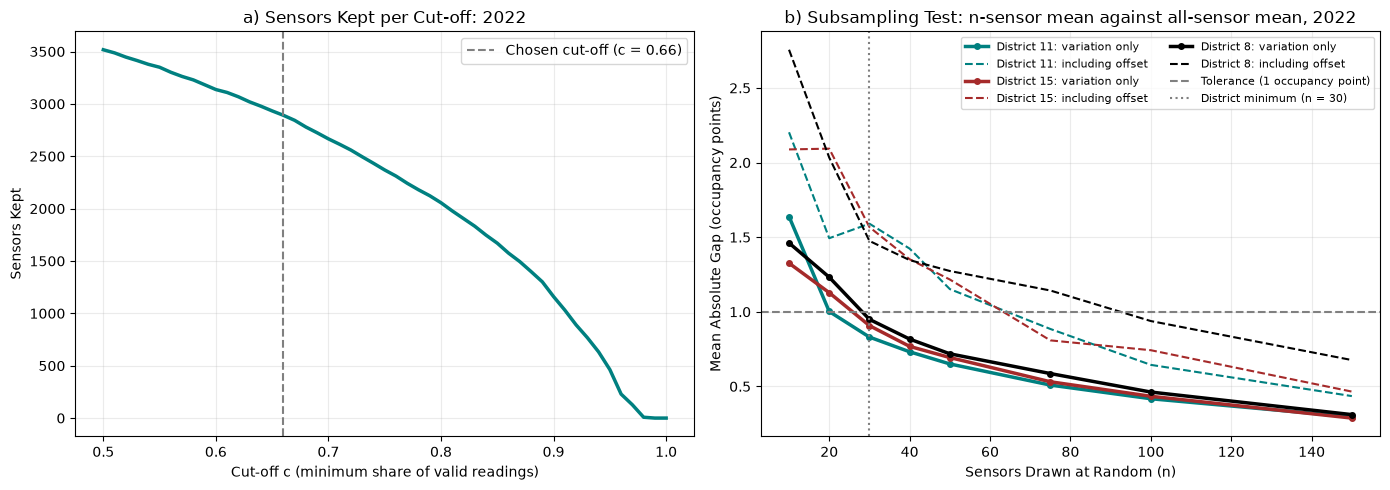

In [43]:
# Figure 3.4: (a) sensors kept per cut-off, (b) the subsampling test behind the district minimum
points_kept = [(point_shares_2022["valid_share"] >= c).sum() for c in cutoffs]  # 2022 sensors kept at each c
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5))
left.plot(cutoffs, points_kept, color=CATEGORY_COLORS[0], linewidth=LINE_WIDTH)
left.axvline(final_c, color=REFERENCE, linewidth=REFERENCE_WIDTH, linestyle="--", label=f"Chosen cut-off (c = {final_c})")
left.set(xlabel="Cut-off c (minimum share of valid readings)", ylabel="Sensors Kept")
left.set_title("a) Sensors Kept per Cut-off: 2022")
left.legend()
for color, district in zip(CATEGORY_COLORS, TEST_DISTRICTS):
    curve = both_measures.filter(pl.col("distrito") == district).sort("n")
    right.plot(curve["n"], curve["mean_wobble"], color=color, linewidth=LINE_WIDTH, marker="o", markersize=4, label=f"District {district}: variation only")
    right.plot(curve["n"], curve["mean_gap"], color=color, linewidth=REFERENCE_WIDTH, linestyle="--", label=f"District {district}: including offset")
right.axhline(TOLERANCE, color=REFERENCE, linewidth=REFERENCE_WIDTH, linestyle="--", label=f"Tolerance ({TOLERANCE:g} occupancy point)")
right.axvline(district_minimum, color=REFERENCE, linewidth=REFERENCE_WIDTH, linestyle=":", label=f"District minimum (n = {district_minimum})")
right.set(xlabel="Sensors Drawn at Random (n)", ylabel="Mean Absolute Gap (occupancy points)")
right.set_title("b) Subsampling Test: n-sensor mean against all-sensor mean, 2022")
right.legend(fontsize=8, ncol=2)
for ax in (left, right):
    style_axes(ax)
fig.tight_layout()
save_figure(fig, "fig-3-4-panel-and-minimum.png")

## 7. Implausible values
Implausible flows and possible stuck-detector occupancies (90–100%) are measured on the panel's 2022
readings, before the flow limit.

shape: (1, 5)
┌──────────┬────────────────┬───────────────┬───────────────┬───────────────────┐
│ readings ┆ flow_over_3000 ┆ flow_over_max ┆ occupancy_100 ┆ occupancy_90_plus │
│ ---      ┆ ---            ┆ ---           ┆ ---           ┆ ---               │
│ u32      ┆ u32            ┆ u32           ┆ u32           ┆ u32               │
╞══════════╪════════════════╪═══════════════╪═══════════════╪═══════════════════╡
│ 85705215 ┆ 63055          ┆ 2145          ┆ 207           ┆ 20747             │
└──────────┴────────────────┴───────────────┴───────────────┴───────────────────┘
sensors with any flow > 5000: 39 | with any occupancy of 100: 38
shape: (10, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 2865.0      │
│ null_count ┆ 0.0         │
│ mean       ┆ 1360.94555  │
│ std        ┆ 2574.163962 │
│ min        ┆ 65.0        │
│ 50%        ┆ 972.0       │
│ 90%        

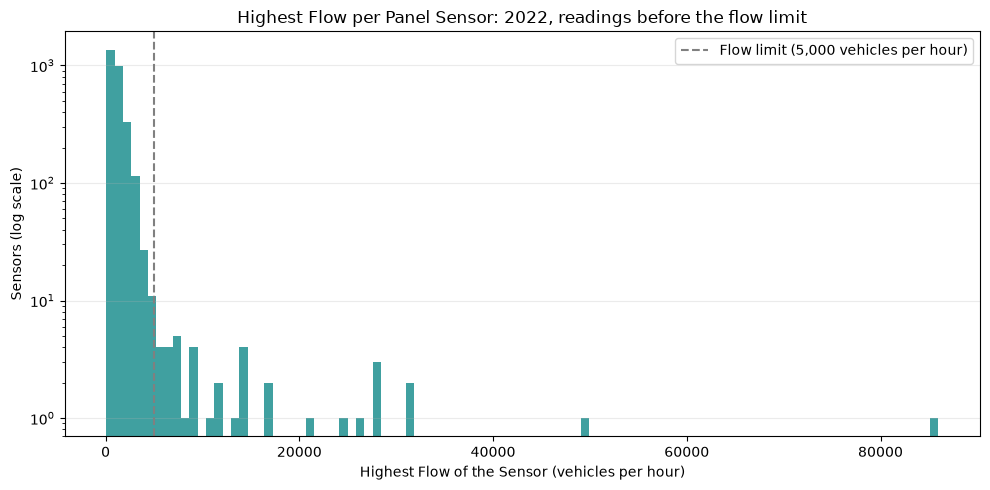

In [44]:
def month_value_profile(month_label: str) -> pl.DataFrame:
    # Per panel sensor, one month: valid readings, highest flow, and counts of very high flows and occupancies.
    return (
        month_urb_rows(month_label, ["id", "intensidad", "ocupacion", "periodo_integracion"])
        .join(final_panel, on="id", how="semi")  # panel sensors only
        .filter(SAMPLES_OK & VALUES_PRESENT)
        .group_by("id")
        .agg(
            readings=pl.len(),
            max_flow=pl.col("intensidad").max(),
            flow_over_3000=(pl.col("intensidad") > 3000).sum(),
            flow_over_max=(pl.col("intensidad") > MAX_FLOW).sum(),  # readings the value rule removes
            occupancy_100=(pl.col("ocupacion") == 100).sum(),
            occupancy_90_plus=(pl.col("ocupacion") >= 90).sum(),
        )
    )


value_profile = (
    pl.concat([month_value_profile(month_label) for month_label in MONTHS_2022])  # one month at a time
    .group_by("id")
    .agg(
        pl.col("readings").sum(),
        pl.col("max_flow").max(),
        pl.col("flow_over_3000").sum(),
        pl.col("flow_over_max").sum(),
        pl.col("occupancy_100").sum(),
        pl.col("occupancy_90_plus").sum(),
    )
)

totals = value_profile.select(pl.exclude("id", "max_flow").sum())  # all panel readings and the counts above
print(totals)
print(f"sensors with any flow > {MAX_FLOW}:", (value_profile["flow_over_max"] > 0).sum(),
      "| with any occupancy of 100:", (value_profile["occupancy_100"] > 0).sum())
print(value_profile["max_flow"].describe(percentiles=[0.5, 0.9, 0.99, 0.999]))  # the highest flow per sensor

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(value_profile["max_flow"], bins=100, log=True, color=CATEGORY_COLORS[0], alpha=0.75)  # log scale: the few broken sensors stay visible
ax.axvline(MAX_FLOW, color=REFERENCE, linewidth=REFERENCE_WIDTH, linestyle="--", label=f"Flow limit ({MAX_FLOW:,} vehicles per hour)")
ax.set(xlabel="Highest Flow of the Sensor (vehicles per hour)", ylabel="Sensors (log scale)")
ax.set_title("Highest Flow per Panel Sensor: 2022, readings before the flow limit")
ax.legend()
style_axes(ax, "y")
fig.tight_layout()
plt.show()

Both are rare, and the highest flow per sensor shows no clean gap from which to set a threshold.

**Decision.** Flows above 5,000 vehicles per hour are invalid (`MAX_FLOW`), based on an earlier
full-data check (not reproduced here) that found only broken sensors above that value. No occupancy
rule is applied.

## 8. District series
District occupancy and flow per slot are means over the panel sensors with a valid reading. The number
of reporting sensors is kept, and empty slots are kept rather than filled. The package builds the
series (`build-district-series`, keyed by slot start); the valid-slot rule is derived here from its
sensor counts.

In [45]:
district_series_2022 = pl.read_parquet(PROCESSED_DATA_DIR / "district-series-2022.parquet")  # built from the same panel
panel_sizes_final = final_panel.group_by("distrito").agg(panel_sensors=pl.len())  # panel size per district
print(district_series_2022.height, district_series_2022["distrito"].n_unique())  # 20 districts x 35,031 slots = 700,620 rows

700620 20


### Valid slots
Three rules are compared by hour and by district: (a) at least 80% of the panel reports; (b) at least
`district_minimum` sensors report; (c) rule (b) and at least half of the panel, so that a small,
possibly non-random subset cannot stand in for a large district.

In [46]:
VALID_COMBINED = (pl.col("sensors") >= district_minimum) & (pl.col("sensors") >= 0.50 * pl.col("panel_sensors"))  # combined rule
EARLIER_REPORTING_SHARE = 0.80  # the earlier rule, no recorded reason (for comparison only)
VALID_80 = pl.col("sensors") >= EARLIER_REPORTING_SHARE * pl.col("panel_sensors")  # earlier rule: 80% of the panel
VALID_MIN_30 = pl.col("sensors") >= district_minimum  # at least 30 sensors only

with_hour = district_series_2022.with_columns(hour=pl.col("slot_start").dt.hour())  # hour of the slot start
hourly_rules = (
    with_hour.group_by("hour")
    .agg(share_80=VALID_80.mean(), share_min_30=VALID_MIN_30.mean(), share_combined=VALID_COMBINED.mean())
    .sort("hour")
)
district_rules = (
    with_hour.group_by("distrito")
    .agg(
        panel_sensors=pl.col("panel_sensors").first(),
        share_80=VALID_80.mean(),
        share_combined=VALID_COMBINED.mean(),
        morning_80=VALID_80.filter(pl.col("hour").is_between(6, 9)).mean(),  # 06:00-09:59 only
        morning_combined=VALID_COMBINED.filter(pl.col("hour").is_between(6, 9)).mean(),
    )
    .sort("morning_combined")
)
with pl.Config(tbl_rows=30):  # all 24 hours and all 20 districts
    print(hourly_rules)
    print(district_rules)

shape: (24, 4)
┌──────┬──────────┬──────────────┬────────────────┐
│ hour ┆ share_80 ┆ share_min_30 ┆ share_combined │
│ ---  ┆ ---      ┆ ---          ┆ ---            │
│ i8   ┆ f64      ┆ f64          ┆ f64            │
╞══════╪══════════╪══════════════╪════════════════╡
│ 0    ┆ 0.87726  ┆ 0.89387      ┆ 0.889658       │
│ 1    ┆ 0.820856 ┆ 0.951267     ┆ 0.935719       │
│ 2    ┆ 0.575551 ┆ 0.821866     ┆ 0.772762       │
│ 3    ┆ 0.582842 ┆ 0.877911     ┆ 0.803048       │
│ 4    ┆ 0.6225   ┆ 0.943664     ┆ 0.865068       │
│ 5    ┆ 0.699966 ┆ 0.944658     ┆ 0.911541       │
│ 6    ┆ 0.309007 ┆ 0.816267     ┆ 0.623322       │
│ 7    ┆ 0.661678 ┆ 0.876473     ┆ 0.78661        │
│ 8    ┆ 0.744041 ┆ 0.893836     ┆ 0.830445       │
│ 9    ┆ 0.805479 ┆ 0.912192     ┆ 0.886267       │
│ 10   ┆ 0.857089 ┆ 0.910445     ┆ 0.902705       │
│ 11   ┆ 0.905959 ┆ 0.911884     ┆ 0.907123       │
│ 12   ┆ 0.928562 ┆ 0.919247     ┆ 0.916164       │
│ 13   ┆ 0.936199 ┆ 0.921986     ┆ 0.918253      

The 80% rule leaves only about a third of the slots starting at 06:00 valid, when complete readings
are rarest. The combined rule keeps most morning slots overall, but several districts keep only
about 50–70% of their 06:00–09:59 slots, and district 19, whose panel equals the minimum, almost none.

**Decision.** A slot is valid under rule (c) (`VALID_COMBINED`). The morning coverage loss is reported
as a consequence of k = 15; the rule is not relaxed to recover it.

In [47]:
# The valid-slot rule: at least the district minimum of sensors AND at least half of the panel report.
assert district_series_2022.select((VALID_COMBINED == pl.col("valid_slot")).all()).item(), "the package's valid_slot differs from rule (c)"
print(district_series_2022.select(pl.col("valid_slot").mean().round(3)).item())  # share of valid district slots in 2022
(
    district_series_2022.group_by("distrito")
    .agg(panel_sensors=pl.col("panel_sensors").first(), valid_share=pl.col("valid_slot").mean())  # per district
    .sort("valid_share")
)

0.881


distrito,panel_sensors,valid_share
i64,u32,f64
19,30,0.118524
2,83,0.835745
9,129,0.851846
18,41,0.857983
1,101,0.86335
8,299,0.889584
16,155,0.903999
14,66,0.926465
5,181,0.928178


### Sensitivity: district occupancy under another k
Not a test of k: district occupancy is rebuilt with k = 13 on the same panel and compared with k = 15
on slots valid under both.

In [48]:
ALTERNATIVE_K = SAMPLES_FULL if MIN_SAMPLES < SAMPLES_FULL else 13  # the comparison version
LOW_K, HIGH_K = sorted((MIN_SAMPLES, ALTERNATIVE_K))


def month_k_comparison(month_label: str) -> pl.DataFrame:
    # Per district and slot, one month: occupancy with the lower and the higher k, same panel, same value rules.
    readings = (
        month_urb_rows(month_label, ["id", "fecha", "intensidad", "ocupacion", "periodo_integracion"])
        .join(final_panel, on="id", how="inner")  # the fixed sensor panel, with districts
        .filter(pl.col("periodo_integracion").is_between(LOW_K, SAMPLES_FULL), VALUES_PRESENT, FLOW_PLAUSIBLE)
    )
    high = pl.col("periodo_integracion") >= HIGH_K  # readings that also count under the higher k (all are at most 15)
    return readings.group_by("distrito", "fecha").agg(
        occupancy_low=pl.col("ocupacion").mean(),
        sensors_low=pl.len(),
        occupancy_high=pl.col("ocupacion").filter(high).mean(),
        sensors_high=high.sum(),
        incomplete=(pl.col("periodo_integracion") < SAMPLES_FULL).sum(),  # readings with fewer than 15 samples
    )


def valid_under(sensors: str) -> pl.Expr:
    # The valid-slot rule (Section 8) applied to one version's count of reporting sensors.
    return (pl.col(sensors) >= district_minimum) & (pl.col(sensors) >= 0.50 * pl.col("panel_sensors"))


k_comparison = (
    pl.concat([month_k_comparison(month_label) for month_label in MONTHS_2022])  # one month at a time
    .join(panel_sizes_final, on="distrito")
    .filter(valid_under("sensors_low"), valid_under("sensors_high"))  # slots valid under both versions
    .with_columns(
        difference=pl.col("occupancy_low") - pl.col("occupancy_high"),  # effect of admitting the extra readings (pp)
        incomplete_share=pl.col("incomplete") / pl.col("sensors_low"),
        hour=(pl.col("fecha") - SLOT).dt.hour(),
    )
)

difference = pl.col("difference")
DIFFERENCE_STATS = [
    pl.len().alias("slots"),
    difference.mean().alias("mean"),
    difference.median().alias("median"),
    difference.abs().mean().alias("mae"),
    difference.abs().quantile(0.95).alias("p95_abs"),
]
print(f"district occupancy with k = {LOW_K} minus k = {HIGH_K} (pp), slots valid under both")
with pl.Config(tbl_rows=30, tbl_cols=-1, float_precision=3):
    print(k_comparison.select(DIFFERENCE_STATS))
    print("06:00-09:59")
    print(k_comparison.filter(pl.col("hour").is_between(6, 9)).select(DIFFERENCE_STATS))
    print(k_comparison.group_by("distrito").agg(DIFFERENCE_STATS).sort("mae", descending=True))
    print("by share of incomplete readings in the slot (band start)")
    print(
        k_comparison.group_by(share_band=((pl.col("incomplete_share") * 10).floor().clip(upper_bound=5) / 10))
        .agg(DIFFERENCE_STATS)
        .sort("share_band")
    )

district occupancy with k = 13 minus k = 15 (pp), slots valid under both
shape: (1, 5)
┌────────┬───────┬────────┬───────┬─────────┐
│ slots  ┆ mean  ┆ median ┆ mae   ┆ p95_abs │
│ ---    ┆ ---   ┆ ---    ┆ ---   ┆ ---     │
│ u32    ┆ f64   ┆ f64    ┆ f64   ┆ f64     │
╞════════╪═══════╪════════╪═══════╪═════════╡
│ 617525 ┆ 0.049 ┆ 0.000  ┆ 0.163 ┆ 0.670   │
└────────┴───────┴────────┴───────┴─────────┘
06:00-09:59
shape: (1, 5)
┌───────┬────────┬────────┬───────┬─────────┐
│ slots ┆ mean   ┆ median ┆ mae   ┆ p95_abs │
│ ---   ┆ ---    ┆ ---    ┆ ---   ┆ ---     │
│ u32   ┆ f64    ┆ f64    ┆ f64   ┆ f64     │
╞═══════╪════════╪════════╪═══════╪═════════╡
│ 91298 ┆ -0.005 ┆ -0.000 ┆ 0.193 ┆ 0.687   │
└───────┴────────┴────────┴───────┴─────────┘
shape: (20, 6)
┌──────────┬───────┬────────┬────────┬───────┬─────────┐
│ distrito ┆ slots ┆ mean   ┆ median ┆ mae   ┆ p95_abs │
│ ---      ┆ ---   ┆ ---    ┆ ---    ┆ ---   ┆ ---     │
│ i64      ┆ u32   ┆ f64    ┆ f64    ┆ f64   ┆ f64     │


Admitting 13–14-sample readings shifts district occupancy little on average, but more in slots where
many readings are incomplete. The comparison cannot cover the morning slots that k = 15 makes
invalid.

shape: (3, 3)
┌──────────┬─────────────┬───────┐
│ distrito ┆ valid_slots ┆ slots │
│ ---      ┆ ---         ┆ ---   │
│ i64      ┆ u32         ┆ u32   │
╞══════════╪═════════════╪═══════╡
│ 1        ┆ 369         ┆ 673   │
│ 11       ┆ 642         ┆ 673   │
│ 19       ┆ 0           ┆ 673   │
└──────────┴─────────────┴───────┘


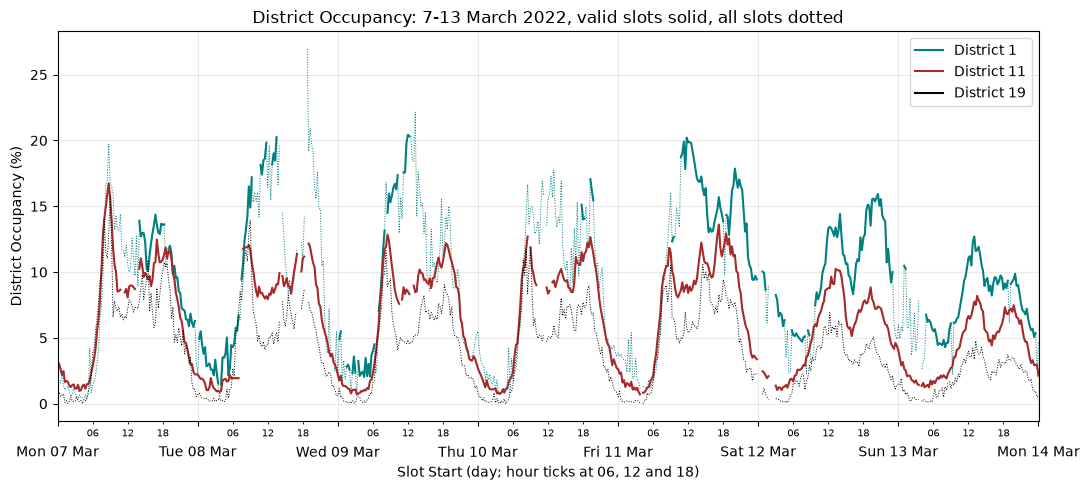

In [49]:
by_size = panel_sizes_final.sort("panel_sensors", descending=True)["distrito"]  # studied districts, largest first
SHOW_DISTRICTS = [1, by_size[0], by_size[-1]]  # the centre, the largest and the smallest district
week = (
    district_series_2022.filter(
        pl.col("slot_start").is_between(datetime(2022, 3, 7), datetime(2022, 3, 14)),  # Monday 7 to Monday 14 March
        pl.col("distrito").is_in(SHOW_DISTRICTS),
    )
    .with_columns(valid_occupancy=pl.when(pl.col("valid_slot")).then(pl.col("occupancy")))  # invalid slots become gaps
)
print(week.group_by("distrito").agg(valid_slots=pl.col("valid_slot").sum(), slots=pl.len()).sort("distrito"))  # valid slots that week

fig, ax = plt.subplots(figsize=(11, 5))
for color, district in zip(CATEGORY_COLORS, SHOW_DISTRICTS):
    one = week.filter(pl.col("distrito") == district)
    ax.plot(one["slot_start"], one["valid_occupancy"], color=color, linewidth=1.5, label=f"District {district}")  # valid slots
    ax.plot(one["slot_start"], one["occupancy"], color=color, linewidth=0.7, linestyle=":")  # every slot, invalid included
ax.xaxis.set_major_locator(mdates.DayLocator())  # one labelled tick per day ...
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))  # ... and small ticks at 06:00, 12:00 and 18:00
ax.xaxis.set_minor_formatter(mdates.DateFormatter("%H"))  # hour only, so the labels do not run together
ax.tick_params(axis="x", which="minor", labelsize=7)
ax.tick_params(axis="x", which="major", pad=14)  # day labels below the hour labels
ax.margins(x=0)  # the axis spans exactly the week
ax.set(xlabel="Slot Start (day; hour ticks at 06, 12 and 18)", ylabel="District Occupancy (%)")
ax.set_title("District Occupancy: 7-13 March 2022, valid slots solid, all slots dotted")
ax.legend()
style_axes(ax)
fig.tight_layout()
plt.show()

Invalid slots are gaps in the solid lines. The smallest district has no valid slot in this week;
its dotted line is the mean over whichever of its sensors reported, which the valid-slot rule rejects.

## 9. Outputs
- `config.py`: `DST_ROWS`, `MIN_SAMPLES` (k = 15), `MAX_FLOW`, `DISTRICT_MINIMUM`, `PANEL_CUTOFFS` and
  `VALID_SLOT_PANEL_SHARE`, applied by `madrid_congestion.districts`.
- District 19 is not studied (notebook 2.0, district support rule).

**Limitation.** Occupancy of 90% or more is kept and has not been checked for stuck detectors.

In [50]:
# The values handed on, all computed above (none typed in by hand).
eda_rows = [row for row in DST_ROWS if row.year in EDA_YEARS]
print("clock-change rows removed in 2022-2023:", len(eda_rows), "| listed for 2024 by the same pattern:", len(DST_ROWS) - len(eda_rows))
print("k = MIN_SAMPLES:", MIN_SAMPLES, "| 2022 URB rows removed (%):",
      k_cost.filter(pl.col("k") == MIN_SAMPLES)["removed_percent"].item())
print("value rule: flow at most", MAX_FLOW, "vehicles per hour")
print("district minimum:", district_minimum, "| panel cut-off c:", final_c, "| panel sensors:", final_panel.height,
      "| districts:", final_panel["distrito"].n_unique())
print("valid district slots in 2022 (share):", district_series_2022.select(pl.col("valid_slot").mean().round(3)).item())
print("valid district slots starting 06:00-09:59 (share):", district_series_2022.filter(
    pl.col("slot_start").dt.hour().is_between(6, 9)).select(pl.col("valid_slot").mean().round(3)).item())

clock-change rows removed in 2022-2023: 10 | listed for 2024 by the same pattern: 5
k = MIN_SAMPLES: 15 | 2022 URB rows removed (%): 20.57
value rule: flow at most 5000 vehicles per hour
district minimum: 30 | panel cut-off c: 0.66 | panel sensors: 2865 | districts: 20
valid district slots in 2022 (share): 0.881
valid district slots starting 06:00-09:59 (share): 0.782
